In [ ]:
!pip install tensorflow
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os
import shutil

import kagglehub

# Download latest version
path = kagglehub.dataset_download("saumyaagrawal1709/opencode-dataset")

print("Path to dataset files:", path)


100%|██████████| 6.26G/6.26G [00:53<00:00, 125MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2


In [ ]:
dataset_path = "/root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset"

In [ ]:
# os.mkdir("dataset")
os.listdir(dataset_path)


['Cassava', 'Tomato', 'Cashew', 'Maize']

In [ ]:
crops = ["Cashew","Cassava","Maize","Tomato"]
folder_path = dataset_path
for crop in crops:
    path1 = os.path.join(folder_path,crop)
    # print(path1)
    path2 = os.path.join(path1,"train_set")
    # print(path2)
    for file in os.listdir(path2):
        # print(file)
        old_file = os.path.join(path2,file)

        filename = str(file)+str("_")+str(crop)

        new_file = os.path.join(path2,filename)
        # print(old_file,new_file)
        os.rename(old_file,new_file)
        print(f"{file} done")

red rust done
anthracnose done
healthy done
gumosis done
leaf miner done
brown spot done
mosaic done
green mite done
bacterial blight done
healthy done
streak virus done
leaf spot done
leaf beetle done
fall armyworm done
leaf blight done
healthy done
grasshoper done
verticulium wilt done
leaf curl done
leaf blight done
healthy done
septoria leaf spot done


In [ ]:
crops = ["Cashew","Cassava","Maize","Tomato"]
folder_path = dataset_path
for crop in crops:
    path1 = os.path.join(folder_path,crop)
    # print(path1)
    path2 = os.path.join(path1,"test_set")
    # print(path2)
    for file in os.listdir(path2):
        # print(file)
        old_file = os.path.join(path2,file)

        filename = str(file)+str("_")+str(crop)

        new_file = os.path.join(path2,filename)
        # print(old_file,new_file)
        os.rename(old_file,new_file)
        print(f"{file} done")

red rust done
anthracnose done
healthy done
gumosis done
leaf miner done
brown spot done
mosaic done
green mite done
bacterial blight done
healthy done
streak virus done
leaf spot done
leaf beetle done
fall armyworm done
leaf blight done
healthy done
grasshoper done
verticulium wilt done
leaf curl done
leaf blight done
healthy done
septoria leaf spot done


In [ ]:
import shutil

path=dataset_path
dest = "/content/dataset"
os.mkdir(dest)
os.mkdir("/content/dataset/test_set")
os.mkdir("/content/dataset/train_set")
subsets = ["train_set","test_set"]
for crop in crops:
    path1 = os.path.join(path,crop)
    for subset in subsets:
        path2 = os.path.join(path1,subset)
        for file in os.listdir(path2):
            source = os.path.join(path2,file)
            dest1 = os.path.join(dest,subset)
            # print(dest1)
            shutil.move(source,dest1)
            print(f"File {source} moved to {dest1}")

File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cashew/train_set/anthracnose_Cashew moved to /content/dataset/train_set
File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cashew/train_set/red rust_Cashew moved to /content/dataset/train_set
File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cashew/train_set/gumosis_Cashew moved to /content/dataset/train_set
File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cashew/train_set/healthy_Cashew moved to /content/dataset/train_set
File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cashew/train_set/leaf miner_Cashew moved to /content/dataset/train_set
File /root/.cache/kagglehub/datasets/saumyaagrawal1709/opencode-dataset/versions/2/Pest and Disease/Dataset/Cash

In [ ]:
os.listdir(dataset_path)

['Cassava', 'Tomato', 'Cashew', 'Maize']

In [ ]:
train_dir = "/content/dataset/train_set"
test_dir = "/content/dataset/test_set"
# train_dir = os.path.join(dataset_path, 'train_set')
# test_dir = os.path.join(dataset_path, 'test_set')

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Define your ImageDataGenerator
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=30,
    width_shift_range=0.2,
    height_shift_range=0.2,
    #  shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='constant',
    validation_split=0.2  # 20% of data will be used for validation
)

# Training data generator
train_generator = train_datagen.flow_from_directory(
    train_dir,  # Root directory where your class folders are stored
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'  # Use 'training' subset
)

# Validation data generator
validation_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'  # Use 'validation' subset
)

test_datagen = ImageDataGenerator(rescale = 1.0/255)
test_generator = test_datagen.flow_from_directory(
    test_dir,  # Root directory where your class folders are stored
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
)
# Now you can use both generators for training and validation


Found 59459 images belonging to 22 classes.
Found 14858 images belonging to 22 classes.
Found 24981 images belonging to 22 classes.


In [ ]:
x = list(train_generator.class_indices)
x
# print(train_generator.class_indices)

['anthracnose_Cashew',
 'bacterial blight_Cassava',
 'brown spot_Cassava',
 'fall armyworm_Maize',
 'grasshoper_Maize',
 'green mite_Cassava',
 'gumosis_Cashew',
 'healthy_Cashew',
 'healthy_Cassava',
 'healthy_Maize',
 'healthy_Tomato',
 'leaf beetle_Maize',
 'leaf blight_Maize',
 'leaf blight_Tomato',
 'leaf curl_Tomato',
 'leaf miner_Cashew',
 'leaf spot_Maize',
 'mosaic_Cassava',
 'red rust_Cashew',
 'septoria leaf spot_Tomato',
 'streak virus_Maize',
 'verticulium wilt_Tomato']

In [ ]:
import numpy as np
images_to_display = {}
for images,labels in train_generator:
    for i in range(len(images)):
        a=np.argmax(labels[i])
        a = x[a]
        if(a not in images_to_display):
            images_to_display[a] = images[i]
            # print(len(images_to_display),len(x))
        if(len(images_to_display)==len(x)):
            break
    if(len(images_to_display)==len(x)):
            break


In [ ]:
images_to_display

{'mosaic_Cassava': array([[[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],
 
        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],
 
        [[0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         ...,
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ],
         [0.        , 0.        , 0.        ]],
 
        ...,
 
        [[0.24472272, 0.3632975 , 0.26102746],
         [0.24480703, 0

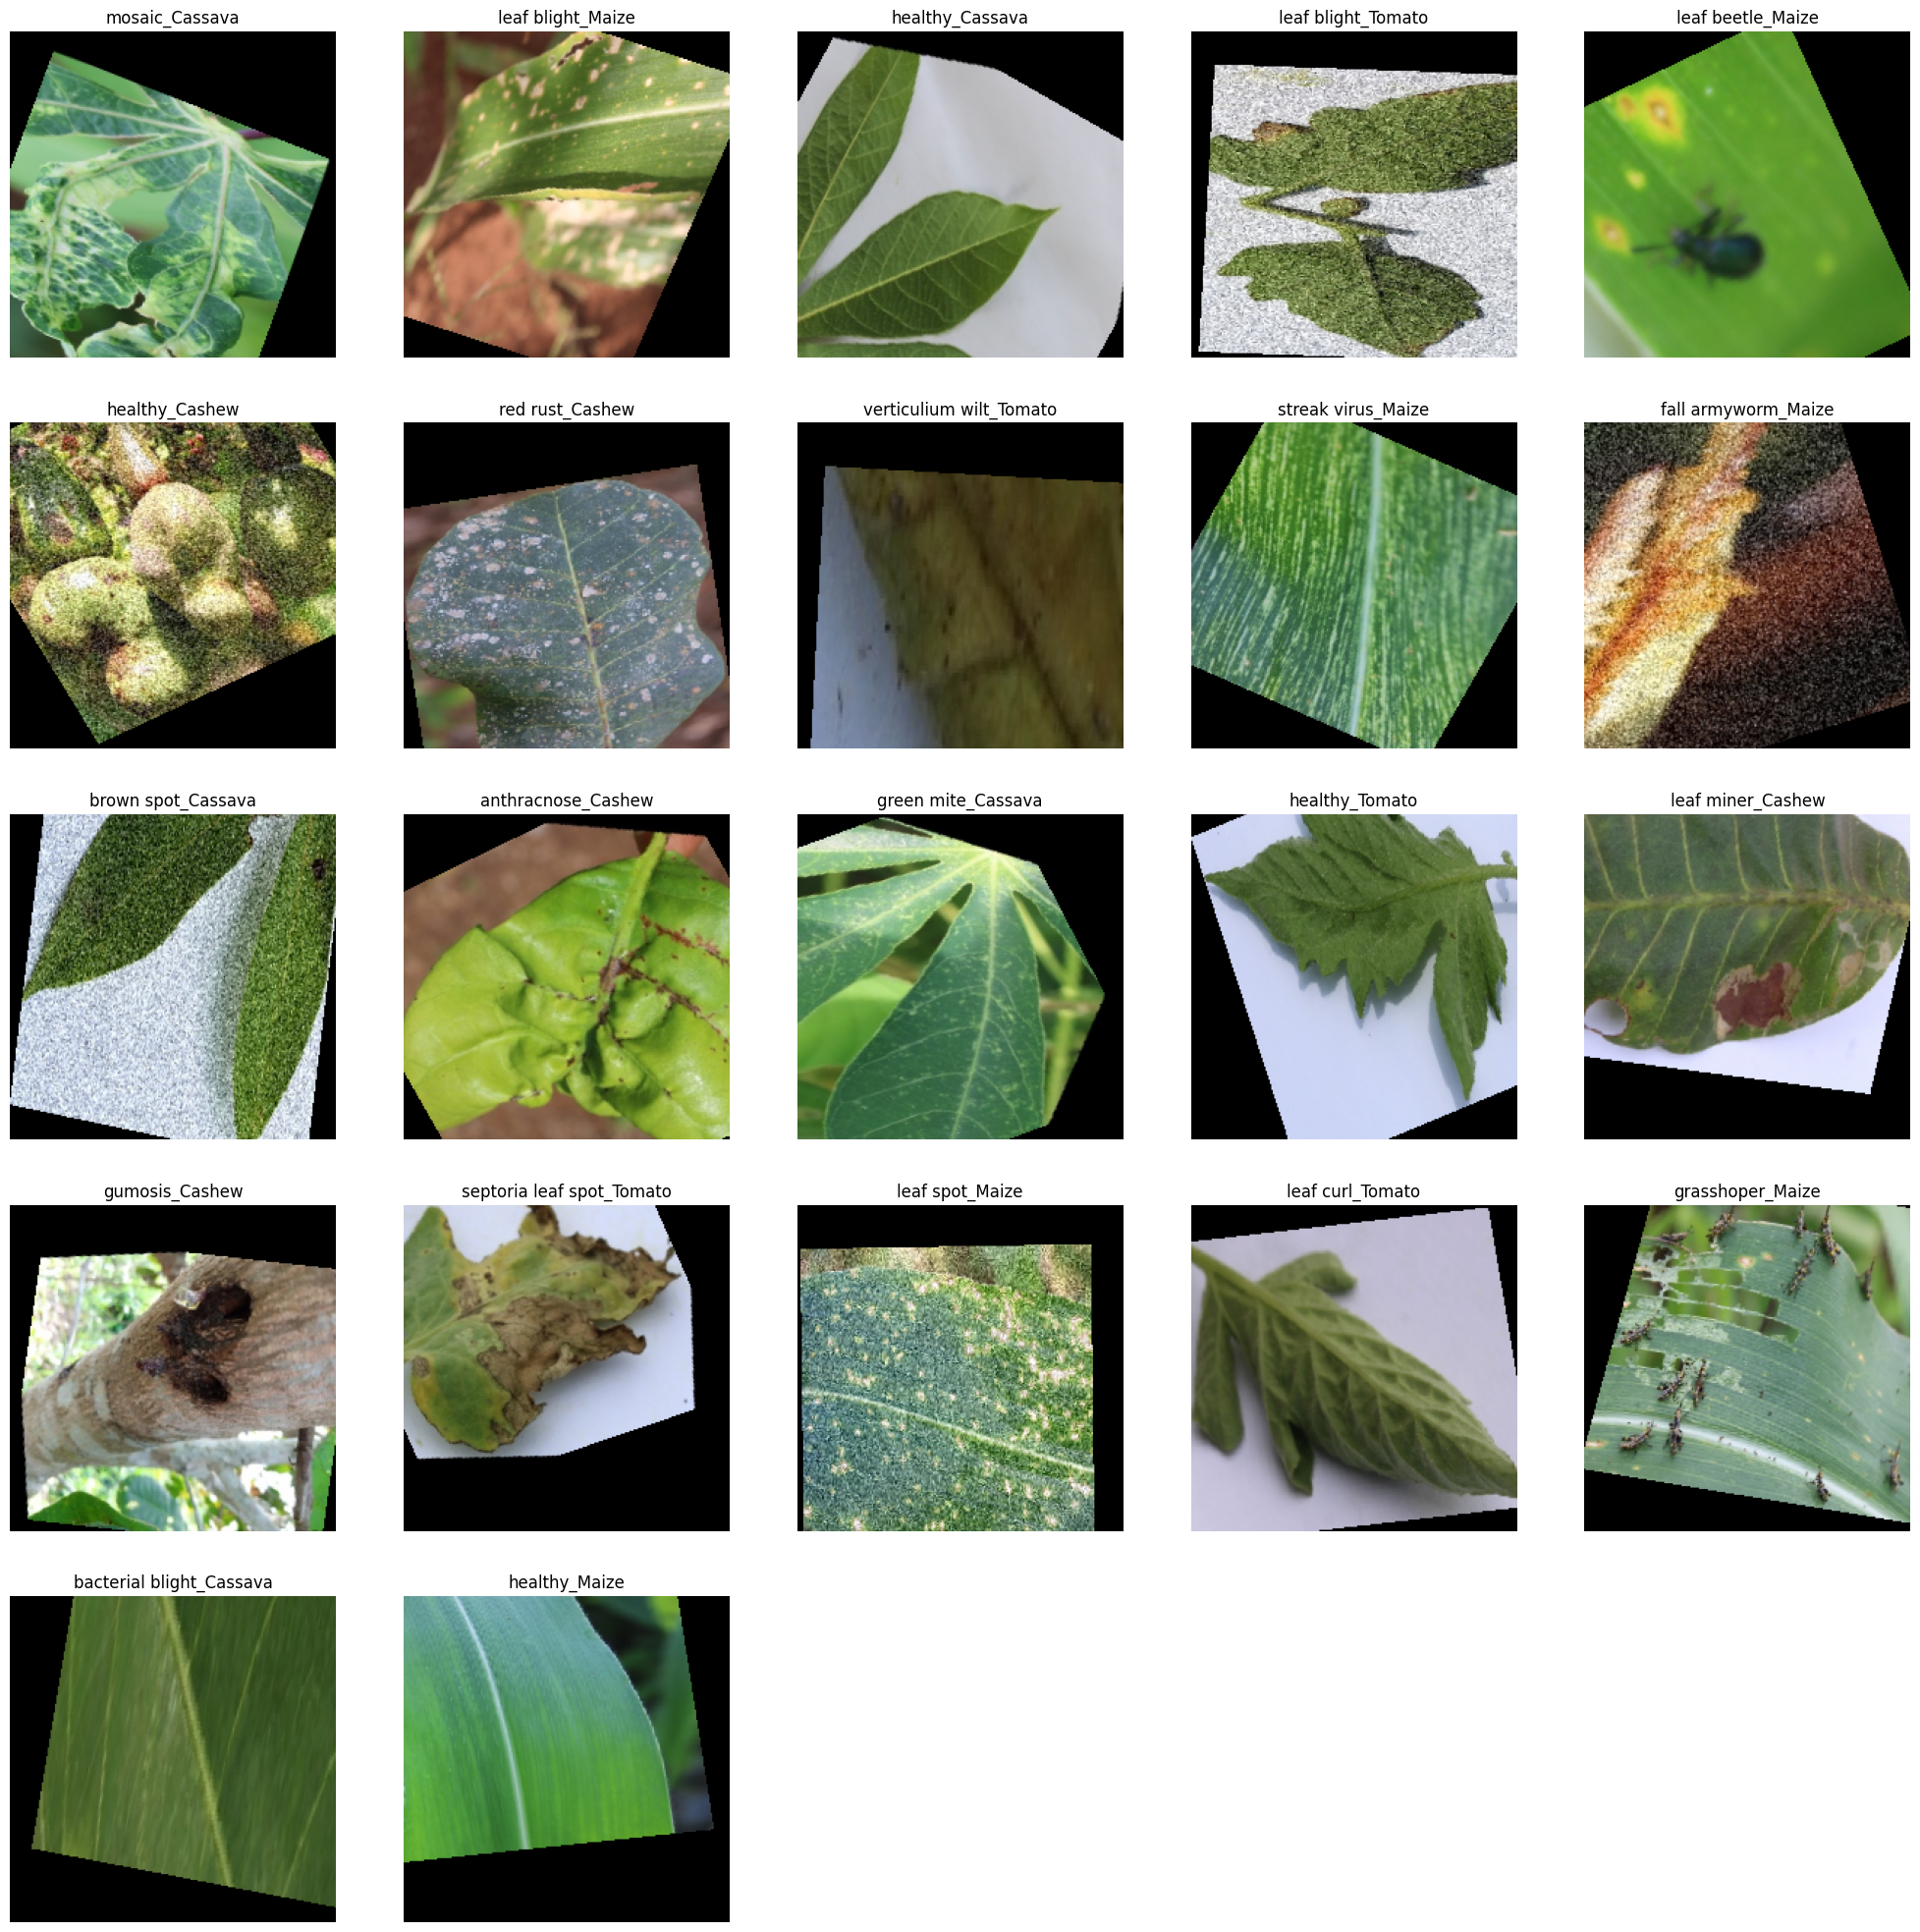

In [ ]:
import matplotlib.pyplot as plt
i=0
plt.figure(figsize=(5*5,5*5))
num_images=22
for label,image in images_to_display.items():
    i+=1
    plt.subplot(5, 5, i)
    plt.axis("off")
    plt.title(label)
    plt.imshow(image)

# plt.tight_layout()
plt.show()



In [ ]:
folder_path = train_dir

In [ ]:
for item in os.listdir(folder_path):
    path = os.path.join(folder_path,item)
    x = os.listdir(path)
    print(len(x))


3789
5200
3102
3241
3250
4751
1714
2575
3246
5877
3024
2250
2000
9373
3100
830
2271
1140
4043
2050
3466
4025


In [ ]:
import os
x = os.listdir(train_dir)
y = os.listdir(test_dir)
print(f"Found {len(x)} files in your train_set")
print(x)
print(f"Found {len(y)} files in your test_set")
print(y)


Found 22 files in your train_set
['leaf beetle_Maize', 'leaf blight_Tomato', 'anthracnose_Cashew', 'bacterial blight_Cassava', 'brown spot_Cassava', 'red rust_Cashew', 'gumosis_Cashew', 'grasshoper_Maize', 'green mite_Cassava', 'healthy_Cashew', 'leaf spot_Maize', 'mosaic_Cassava', 'healthy_Tomato', 'septoria leaf spot_Tomato', 'verticulium wilt_Tomato', 'healthy_Maize', 'healthy_Cassava', 'fall armyworm_Maize', 'streak virus_Maize', 'leaf curl_Tomato', 'leaf miner_Cashew', 'leaf blight_Maize']
Found 22 files in your test_set
['leaf beetle_Maize', 'leaf blight_Tomato', 'anthracnose_Cashew', 'bacterial blight_Cassava', 'brown spot_Cassava', 'red rust_Cashew', 'gumosis_Cashew', 'grasshoper_Maize', 'green mite_Cassava', 'healthy_Cashew', 'leaf spot_Maize', 'mosaic_Cassava', 'healthy_Tomato', 'septoria leaf spot_Tomato', 'verticulium wilt_Tomato', 'healthy_Maize', 'healthy_Cassava', 'fall armyworm_Maize', 'streak virus_Maize', 'leaf curl_Tomato', 'leaf miner_Cashew', 'leaf blight_Maize']


In [ ]:
train_set = train_dir
test_set = test_dir

In [ ]:
!pip install opencv-python
import cv2


In [ ]:
# import os
# import cv2
# import numpy as np
# from tensorflow.keras.preprocessing.image import ImageDataGenerator

# # Set the paths
# train_dir = train_dir
# classes = os.listdir(train_dir)  # Get all classes (folders) in the train_set directory

# # Create an ImageDataGenerator instance for augmentation
# datagen = ImageDataGenerator(
#     rotation_range=40,       # Random rotation
#     width_shift_range=0.2,   # Random width shift
#     height_shift_range=0.2,  # Random height shift
#     shear_range=0.2,         # Random shear
#     zoom_range=0.2,          # Random zoom
#     horizontal_flip=True,    # Random horizontal flip
#     fill_mode='nearest'      # Fill mode for pixels after transformation
# )

# # Function to generate augmented images and save them
# def augment_images_for_class(class_name, num_augmented_images=3500):
#     class_dir = os.path.join(train_dir, class_name)
#     # Get all images in the class directory
#     images = [os.path.join(class_dir, img) for img in os.listdir(class_dir) if img.endswith(('JPG', 'jpeg', 'png'))]
#     print(len(images))
#     for image_path in (images):
#         # np.random.shuffle(images)
#         # image_path = images[0]
#         print(image_path)
#         # print("a")
#         img = cv2.imread(image_path)  # Read the image
#         img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert BGR to RGB

#         # Reshape the image for the ImageDataGenerator
#         img = img.reshape((1,) + img.shape)  # Add batch size dimension (1, height, width, channels)

#         # Generate augmented images and save them
#         i = len(os.listdir(class_dir))
#         # print(i)
#         for batch in datagen.flow(img, batch_size=1, save_to_dir=class_dir, save_prefix='aug', save_format='jpeg'):
#             # print(batch)
#             i += 1
#             # print(i)
#             break
#         if i >= num_augmented_images:
#             # print(i)
#             break

# # Loop through the classes and augment images for minority classes
# for class_name in classes:
#     augment_images_for_class(class_name, num_augmented_images=3500)
#     print(f"Augmented images for class {class_name}")

# print("Augmentation complete!")


In [ ]:
for item in os.listdir(folder_path):
    path = os.path.join(folder_path,item)
    x = os.listdir(path)

    print(path,len(x))


/content/dataset/train_set/leaf beetle_Maize 3789
/content/dataset/train_set/leaf blight_Tomato 5200
/content/dataset/train_set/anthracnose_Cashew 3102
/content/dataset/train_set/bacterial blight_Cassava 3241
/content/dataset/train_set/brown spot_Cassava 3250
/content/dataset/train_set/red rust_Cashew 4751
/content/dataset/train_set/gumosis_Cashew 1714
/content/dataset/train_set/grasshoper_Maize 2575
/content/dataset/train_set/green mite_Cassava 3246
/content/dataset/train_set/healthy_Cashew 5877
/content/dataset/train_set/leaf spot_Maize 3024
/content/dataset/train_set/mosaic_Cassava 2250
/content/dataset/train_set/healthy_Tomato 2000
/content/dataset/train_set/septoria leaf spot_Tomato 9373
/content/dataset/train_set/verticulium wilt_Tomato 3100
/content/dataset/train_set/healthy_Maize 830
/content/dataset/train_set/healthy_Cassava 2271
/content/dataset/train_set/fall armyworm_Maize 1140
/content/dataset/train_set/streak virus_Maize 4043
/content/dataset/train_set/leaf curl_Tomato 20

In [ ]:
train_dir=train_set

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from keras.layers import Dense, Dropout, Activation, Flatten, Conv2D, MaxPooling2D,BatchNormalization,GlobalAveragePooling2D

In [ ]:
import os
from collections import defaultdict

data_dir = train_dir  # change this to your dataset path
class_counts = {}

for class_name in os.listdir(data_dir):
    class_path = os.path.join(data_dir, class_name)
    if not os.path.isdir(class_path):
        continue
    count = len([f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.png', '.jpeg'))])
    class_counts[class_name] = count

max_count = max(class_counts.values())
max_count = min(max_count,4000)
print("Class counts:", class_counts)


Class counts: {'leaf beetle_Maize': 3789, 'leaf blight_Tomato': 5200, 'anthracnose_Cashew': 3102, 'bacterial blight_Cassava': 3241, 'brown spot_Cassava': 3250, 'red rust_Cashew': 4751, 'gumosis_Cashew': 1714, 'grasshoper_Maize': 2575, 'green mite_Cassava': 3246, 'healthy_Cashew': 5877, 'leaf spot_Maize': 3024, 'mosaic_Cassava': 2250, 'healthy_Tomato': 2000, 'septoria leaf spot_Tomato': 9373, 'verticulium wilt_Tomato': 3100, 'healthy_Maize': 830, 'healthy_Cassava': 2271, 'fall armyworm_Maize': 1140, 'streak virus_Maize': 4043, 'leaf curl_Tomato': 2050, 'leaf miner_Cashew': 3466, 'leaf blight_Maize': 4025}


In [ ]:
import cv2
import numpy as np
import random

def augment_image(image):
    aug_type = random.choice(['rotate', 'flip', 'bright', 'blur'])
    if aug_type == 'rotate':
        angle = random.randint(-30, 30)
        h, w = image.shape[:2]
        M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1)
        return cv2.warpAffine(image, M, (w, h), borderMode=cv2.BORDER_REFLECT)
    elif aug_type == 'flip':
        return cv2.flip(image, 1)
    elif aug_type == 'bright':
        factor = 0.5 + np.random.uniform()
        return cv2.convertScaleAbs(image, alpha=factor, beta=0)
    elif aug_type == 'blur':
        return cv2.GaussianBlur(image, (5, 5), 0)
    return image


In [ ]:
from tqdm import tqdm

for class_name, count in tqdm(class_counts.items()):
    class_path = os.path.join(data_dir, class_name)
    images = [f for f in os.listdir(class_path) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]

    # How many to add
    to_generate = max_count - count
    if to_generate <= 0:
        continue

    i = 0
    while i < to_generate:
        img_file = random.choice(images)
        img_path = os.path.join(class_path, img_file)
        image = cv2.imread(img_path)
        if image is None:
            continue

        aug_img = augment_image(image)
        new_name = f"{os.path.splitext(img_file)[0]}_aug{i}.jpg"
        cv2.imwrite(os.path.join(class_path, new_name), aug_img)
        i += 1


100%|██████████| 22/22 [01:33<00:00,  4.24s/it]


In [ ]:
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')

import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,                        # your single dataset directory
    validation_split=0.2,            # 20% validation
    subset="training",               # use 80% for training
    seed=123,                        # ensures consistent split
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,                        # same directory
    validation_split=0.2,            # same 20% split
    subset="validation",             # use 20% for validation
    seed=123,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)




Found 97269 files belonging to 22 classes.
Using 77816 files for training.
Found 97269 files belonging to 22 classes.
Using 19453 files for validation.


In [ ]:
# from tensorflow.keras.applications import MobileNet  # or EfficientNetB0, etc.
# from tensorflow.keras.models     import Sequential
# from tensorflow.keras.layers     import GlobalAveragePooling2D, Dropout, Dense
# from tensorflow.keras.optimizers import Adam

# base = MobileNet(
#     weights='imagenet',
#     include_top=False,
#     input_shape=(*IMAGE_SIZE,3),
# )
# base.trainable = False

# model = Sequential([
#     base,
#     GlobalAveragePooling2D(),
#     Dropout(0.3),
#     Dense(256, activation='relu'),
#     Dropout(0.4),
#     Dense(22, activation='softmax', dtype='float32'),  # ensure FP32 outputs
# ])

# # jit_compile fuses kernels for speed
# model.compile(
#     optimizer=Adam(1e-3),
#     loss='categorical_crossentropy',
#     metrics=['accuracy'],
#     jit_compile=True
# )

# model.summary()

# # —————————————— 6) TRAIN ——————————————
# history = model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=5,
# )

In [ ]:
import tensorflow as tf
print("Num GPUs Available:", len(tf.config.list_physical_devices('GPU')))


Num GPUs Available: 1


In [ ]:
# #Model Architecture
# model = Sequential()

# model.add(Conv2D(32, kernel_size= 3,padding="same", activation='relu', input_shape=(224, 224, 3)))
# model.add(Conv2D(32, kernel_size= 3, activation='relu'))
# model.add(MaxPooling2D(pool_size=2, strides=2))


# model.add(Conv2D(64, kernel_size= 3,padding="same", activation='relu', input_shape=(224, 224, 3)))
# model.add(Conv2D(64, kernel_size= 3, activation='relu'))
# model.add(MaxPooling2D(pool_size=2, strides=2))

# model.add(Conv2D(128, kernel_size= 3,padding="same", activation='relu', input_shape=(224, 224, 3)))
# model.add(Conv2D(128, kernel_size= 3, activation='relu'))
# model.add(MaxPooling2D(pool_size=2, strides=2))

# model.add(Conv2D(256, kernel_size= 3,padding="same", activation='relu', input_shape=(224, 224, 3)))
# model.add(Conv2D(256, kernel_size= 3, activation='relu'))
# model.add(MaxPooling2D(pool_size=2, strides=2))


# model.add(Dropout(0.25))
# model.add(Flatten())
# model.add(Dense(256, activation='relu'))
# model.add(Dropout(0.4))
# model.add(Dense(22, activation='softmax'))
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy('mixed_float16')


from tensorflow.keras import Sequential
from tensorflow.keras.applications import EfficientNetB0,MobileNet
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

# 1) Load EfficientNetB0 without its top classifier
base = EfficientNetB0(
    weights='imagenet',      # pretrained on ImageNet
    include_top=False,       # strip off its original classifier
    input_shape=(224,224,3), # match your data
              # width multiplier: 0.5, 0.75, or 1.0
)

# 2) Build your model head on top
model = Sequential([
    base,                                # the MobileNet backbone
    GlobalAveragePooling2D(),            # collapse H×W
    Dropout(0.3),                        # regularize a bit
    Dense(256, activation='relu'),       # your custom dense layer
    Dropout(0.4),
    Dense(22, activation='softmax')      # 22 classes
])

# 3) Freeze backbone for initial training
base.trainable = False

# 4) Compile
model.compile(
    optimizer=Adam(1e-3),
    loss='categorical_crossentropy',  # or 'sparse_categorical_crossentropy' if using sparse labels
    metrics=['accuracy']
)

model.summary()

# 5) Train head only
model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    batch_size=64,
    # class_weight=class_weights
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,383,161 (16.72 MB)

 Trainable params: 333,590 (1.27 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/5
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 260s 189ms/step - accuracy: 0.6224 - loss: 1.1432 - val_accuracy: 0.8090 - val_loss: 0.5284
Epoch 2/5
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 196s 161ms/step - accuracy: 0.7651 - loss: 0.6540 - val_accuracy: 0.8190 - val_loss: 0.4840
Epoch 3/5
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 192s 157ms/step - accuracy: 0.7811 - loss: 0.6006 - val_accuracy: 0.8332 - val_loss: 0.4476
Epoch 4/5
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 202s 157ms/step - accuracy: 0.7935 - loss: 0.5650 - val_accuracy: 0.8444 - val_loss: 0.4213
Epoch 5/5
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 184s 151ms/step - accuracy: 0.8013 - loss: 0.5396 - val_accuracy: 0.8468 - val_loss: 0.4096


In [ ]:
base.trainable = True
for layer in base.layers[:-20]:
    layer.trainable = False

# Recompile with lower learning rate
from tensorflow.keras.optimizers import Adam
model.compile(optimizer=Adam(1e-5), loss='categorical_crossentropy', metrics=['accuracy'])

# Continue training
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10  # You can increase further
)

Epoch 1/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 251s 178ms/step - accuracy: 0.6763 - loss: 1.0913 - val_accuracy: 0.8267 - val_loss: 0.4786
Epoch 2/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 188s 155ms/step - accuracy: 0.7686 - loss: 0.6722 - val_accuracy: 0.8424 - val_loss: 0.4327
Epoch 3/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 197s 162ms/step - accuracy: 0.7919 - loss: 0.5909 - val_accuracy: 0.8510 - val_loss: 0.4088
Epoch 4/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 191s 153ms/step - accuracy: 0.8034 - loss: 0.5434 - val_accuracy: 0.8570 - val_loss: 0.3928
Epoch 5/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 195s 160ms/step - accuracy: 0.8132 - loss: 0.5151 - val_accuracy: 0.8606 - val_loss: 0.3803
Epoch 6/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 193s 152ms/step - accuracy: 0.8205 - loss: 0.4922 - val_accuracy: 0.8644 - val_loss: 0.3697
Epoch 7/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 195s 160ms/step - accuracy: 0.8280 - loss: 0.4662 - val_accuracy: 0.8666 - val_loss: 0.3612
Epoch 8/10
1216/1216 ━━━━━━━━━━━━━━━━━━━━ 201s 160ms/step - ac

In [ ]:
model.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenet_1.00_224 (Functional) │ (None, 7, 7, 1024)     │     3,228,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_10     │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_22 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_23 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 22)             │         5,654 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,496,918 (13.34 MB)

 Trainable params: 3,200,278 (12.21 MB)

 Non-trainable params: 296,640 (1.13 MB)

In [ ]:
rprint("Labels shape from train_generator:", train_generator.labels.shape)

NameError: name 'rprint' is not defined

In [ ]:
steps_per_epoch = len(train_generator)  # Number of batches in the training generator
validation_steps = len(validation_generator)

In [ ]:
print(steps_per_epoch,validation_steps)

1859 465


In [ ]:
print("Number of classes:", train_generator.num_classes)
print("Class indices:", train_generator.class_indices)  # Dictionary of class names and indices
print("Number of classes:", len(train_generator.class_indices))

Number of classes: 22
Class indices: {'anthracnose_Cashew': 0, 'bacterial blight_Cassava': 1, 'brown spot_Cassava': 2, 'fall armyworm_Maize': 3, 'grasshoper_Maize': 4, 'green mite_Cassava': 5, 'gumosis_Cashew': 6, 'healthy_Cashew': 7, 'healthy_Cassava': 8, 'healthy_Maize': 9, 'healthy_Tomato': 10, 'leaf beetle_Maize': 11, 'leaf blight_Maize': 12, 'leaf blight_Tomato': 13, 'leaf curl_Tomato': 14, 'leaf miner_Cashew': 15, 'leaf spot_Maize': 16, 'mosaic_Cassava': 17, 'red rust_Cashew': 18, 'septoria leaf spot_Tomato': 19, 'streak virus_Maize': 20, 'verticulium wilt_Tomato': 21}
Number of classes: 22


In [ ]:
# Evaluate the model on the test set using test_generator
test_loss, test_accuracy = model.evaluate(test_generator, steps=780, verbose=1)

# Print the results
print(f"Test Loss: {test_loss}")
print(f"Test Accuracy: {test_accuracy}")


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


780/780 ━━━━━━━━━━━━━━━━━━━━ 122s 143ms/step - accuracy: 0.0492 - loss: 3.0426
Test Loss: 3.0458385944366455
Test Accuracy: 0.05060096085071564


In [ ]:
import tensorflow as tf

# Load test dataset
test_dir = "/content/dataset/test_set"  # Replace with your path

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(224, 224),
    batch_size=32,
    shuffle=False  # ⚠ Important for correct evaluation
)


Found 24981 files belonging to 22 classes.


In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input

AUTOTUNE = tf.data.AUTOTUNE

def preprocess(image, label):
    return preprocess_input(image), label

test_ds = test_ds.map(preprocess).prefetch(buffer_size=AUTOTUNE)

import tensorflow as tf

NUM_CLASSES = 22  # update if needed

def one_hot_encode(x, y):
    return x, tf.one_hot(y, depth=NUM_CLASSES)

test_ds = test_ds.map(one_hot_encode)


In [ ]:
# Evaluate the test set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test Accuracy: {test_acc * 100:.2f}%")


781/781 ━━━━━━━━━━━━━━━━━━━━ 54s 69ms/step - accuracy: 0.8568 - loss: 0.4249
Test Accuracy: 85.87%


In [ ]:
!pip install transformers datasets


In [ ]:
from transformers import create_optimizer
from transformers import TFViTForImageClassification

model = TFViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224-in21k", num_labels=22
)

# ✅ Use Hugging Face's optimizer creation method
optimizer, _ = create_optimizer(
    init_lr=3e-5,
    num_warmup_steps=0,
    num_train_steps=1000  # Change as per your dataset
)

# ✅ Use standard loss and metrics
loss = tf.keras.losses.CategoricalCrossentropy(from_logits=True)
metrics = ['accuracy']

# ✅ This will now work without errors
model.compile(optimizer=optimizer, loss=loss, metrics=metrics)


Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFViTForImageClassification: ['pooler.dense.bias', 'pooler.dense.weight']
- This IS expected if you are initializing TFViTForImageClassification from a PyTorch model trained on another task or with another architecture (e.g. initializing a TFBertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFViTForImageClassification from a PyTorch model that you expect to be exactly identical (e.g. initializing a TFBertForSequenceClassification model from a BertForSequenceClassification model).
Some weights or buffers of the TF 2.0 model TFViTForImageClassification were not initialized from the PyTorch model and are newly initialized: ['classifier.weight', 'classifier.bias']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

# Step A: load already‐batched dataset
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    batch_size=32,
    image_size=(224,224),
    label_mode='categorical',  # one-hot
    validation_split=0.2,
    subset='training',
    seed=123
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    train_dir,
    batch_size=32,
    image_size=(224,224),
    label_mode='categorical',
    validation_split=0.2,
    subset='validation',
    seed=123
)

# Step B: preprocessing (no re-batching!)
def preprocess_tf(image, label):
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = (image - 0.5) * 2.0        # normalize to [-1,1]
    image = tf.transpose(image, [2,0,1])  # CHW for TF ViT
    return image, label

train_ds = (
    train_ds
    .map(preprocess_tf, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)

val_ds = (
    val_ds
    .map(preprocess_tf, num_parallel_calls=AUTOTUNE)
    .prefetch(AUTOTUNE)
)


Found 97269 files belonging to 22 classes.
Using 77816 files for training.
Found 97269 files belonging to 22 classes.
Using 19453 files for validation.


ValueError: in user code:

    File "/tmp/ipython-input-56-3436702232.py", line 28, in preprocess_tf  *
        image = tf.transpose(image, [2,0,1])  # CHW for TF ViT

    ValueError: Dimension must be 4 but is 3 for '{{node transpose}} = Transpose[T=DT_FLOAT, Tperm=DT_INT32](mul, transpose/perm)' with input shapes: [?,224,224,3], [3].


In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)


Epoch 1/5


ValueError: in user code:

    File "/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py", line 1398, in train_function  *
        return step_function(self, iterator)
    File "/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py", line 1381, in step_function  **
        outputs = model.distribute_strategy.run(run_step, args=(data,))
    File "/usr/local/lib/python3.11/dist-packages/tf_keras/src/engine/training.py", line 1370, in run_step  **
        outputs = model.train_step(data)
    File "/usr/local/lib/python3.11/dist-packages/transformers/modeling_tf_utils.py", line 1652, in train_step
        y_pred = self(x, training=True)
    File "/usr/local/lib/python3.11/dist-packages/tf_keras/src/utils/traceback_utils.py", line 70, in error_handler
        raise e.with_traceback(filtered_tb) from None
    File "/tmp/__autograph_generated_filetmipgwu3.py", line 40, in tf__run_call_with_unpacked_inputs
        raise
    File "/tmp/__autograph_generated

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-5),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)


ValueError: Could not interpret optimizer identifier: <keras.src.optimizers.adam.Adam object at 0x7f0768b3b010>

In [ ]:
for x_batch, y_batch in train_ds.take(1):
    print("x:", x_batch.shape)
    print("y:", y_batch.shape)
    break


x: (32, 3, 224, 224)
y: (32, 64, 22)


In [ ]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# Hugging Face:
from transformers import ViTFeatureExtractor, ViTForImageClassification, get_scheduler
# PyTorch:
from torch.optim import AdamW

# ── 1) SETTINGS ──────────────────────────────────────────────────────────────
DATA_DIR    = "/content/dataset/train_set"
NUM_CLASSES = 22
BATCH_SIZE  = 32
IMG_SIZE    = 224
EPOCHS      = 5
LR          = 3e-5
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

# ── 2) FEATURE EXTRACTOR & TRANSFORMS ─────────────────────────────────────────
feature_extractor = ViTFeatureExtractor.from_pretrained("google/vit-base-patch16-224-in21k")

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=feature_extractor.image_mean,
                         std=feature_extractor.image_std),
])
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=feature_extractor.image_mean,
                         std=feature_extractor.image_std),
])

# ── 3) DATASETS & DATALOADERS ──────────────────────────────────────────────────
full_dataset = datasets.ImageFolder(DATA_DIR, transform=train_transform)
num_train = int(0.8 * len(full_dataset))
num_val   = len(full_dataset) - num_train
train_ds, val_ds = torch.utils.data.random_split(full_dataset, [num_train, num_val])
# swap in val_transform for val set
val_ds.dataset.transform = val_transform

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

# ── 4) MODEL SETUP ────────────────────────────────────────────────────────────
model = ViTForImageClassification.from_pretrained(
    "google/vit-base-patch16-224-in21k",
    num_labels=NUM_CLASSES,
)
model.to(DEVICE)

# ── 5) OPTIMIZER & SCHEDULER ───────────────────────────────────────────────────
optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

num_training_steps = len(train_loader) * EPOCHS
lr_scheduler = get_scheduler(
    name="linear",
    optimizer=optimizer,
    num_warmup_steps=num_training_steps // 10,
    num_training_steps=num_training_steps,
)

# ── 6) TRAINING LOOP (with optional AMP) ──────────────────────────────────────
criterion = nn.CrossEntropyLoss()
scaler = torch.cuda.amp.GradScaler()  # comment out if no AMP

for epoch in range(EPOCHS):
    model.train()
    train_loss = train_correct = train_total = 0

    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(pixel_values=images).logits
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        lr_scheduler.step()

        train_loss += loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc   = train_correct / train_total

    model.eval()
    val_loss = val_correct = val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(pixel_values=images).logits
            loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
    val_loss /= val_total
    val_acc   = val_correct / val_total

    print(f"Epoch {epoch+1}/{EPOCHS} — "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} — "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

# ── 7) SAVE ───────────────────────────────────────────────────────────────────
model.save_pretrained("vit-finetuned-cropdisease")
model.save_pretrained('/content/drive/MyDrive/vit-cropdisease')


/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

/usr/local/lib/python3.11/dist-packages/transformers/models/vit/feature_extraction_vit.py:30: FutureWarning: The class ViTFeatureExtractor is deprecated and will be removed in version 5 of Transformers. Please use ViTImageProcessor instead.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Some weights of ViTForImageClassification were not initialized from the model checkpoint at google/vit-base-patch16-224-in21k and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
/tmp/ipython-input-32-1288119268.py:70: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()  # comment out if no AMP
/tmp/ipython-input-32-1288119268.py:80: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1/5 — Train Loss: 1.0947, Train Acc: 0.7630 — Val Loss: 0.3211, Val Acc: 0.9040
Epoch 2/5 — Train Loss: 0.2105, Train Acc: 0.9361 — Val Loss: 0.1796, Val Acc: 0.9417
Epoch 3/5 — Train Loss: 0.0876, Train Acc: 0.9741 — Val Loss: 0.1513, Val Acc: 0.9519
Epoch 4/5 — Train Loss: 0.0400, Train Acc: 0.9893 — Val Loss: 0.1410, Val Acc: 0.9581
Epoch 5/5 — Train Loss: 0.0208, Train Acc: 0.9950 — Val Loss: 0.1289, Val Acc: 0.9613


In [33]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from transformers import ViTFeatureExtractor, ViTForImageClassification
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# ── 1) SETTINGS ──────────────────────────────────────────────────────────────
TEST_DIR    = "/content/dataset/test_set"  # your test‐set root, with subfolders per class
BATCH_SIZE  = 32
IMG_SIZE    = 224
DEVICE      = "cuda" if torch.cuda.is_available() else "cpu"

# ── 2) TRANSFORMS & DATA LOADER ──────────────────────────────────────────────
# We’ll use the same mean/std as before to mirror training
# feature_extractor = ViTFeatureExtractor.from_pretrained("vit-finetuned-cropdisease")
from transformers import ViTFeatureExtractor

# Use the SAME extractor you used for training
feature_extractor = ViTFeatureExtractor.from_pretrained("google/vit-base-patch16-224-in21k")

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=feature_extractor.image_mean,
                         std=feature_extractor.image_std),
])

test_dataset = datasets.ImageFolder(TEST_DIR, transform=test_transform)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

# ── 3) LOAD MODEL ─────────────────────────────────────────────────────────────
model = ViTForImageClassification.from_pretrained("vit-finetuned-cropdisease")
model.to(DEVICE)
model.eval()

# ── 4) RUN INFERENCE ──────────────────────────────────────────────────────────
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        logits = model(pixel_values=images).logits
        preds = logits.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

# ── 5) METRICS ────────────────────────────────────────────────────────────────
# 5.1 Overall accuracy
accuracy = (all_preds == all_labels).mean()
print(f"Test Accuracy: {accuracy * 100:.2f}%")

# 5.2 Per‐class precision/recall/F1
class_names = test_dataset.classes  # index→name
print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 5.3 Confusion matrix (optional)
cm = confusion_matrix(all_labels, all_preds)
print("Confusion Matrix:\n", cm)


Test Accuracy: 95.60%

Classification Report:

                           precision    recall  f1-score   support

       anthracnose_Cashew       0.96      0.92      0.94      1838
 bacterial blight_Cassava       0.97      0.91      0.94      2623
       brown spot_Cassava       0.89      0.97      0.92      1483
      fall armyworm_Maize       0.96      1.00      0.98       284
         grasshoper_Maize       0.99      1.00      1.00       411
       green mite_Cassava       0.94      0.97      0.95      1020
           gumosis_Cashew       0.99      1.00      0.99       425
           healthy_Cashew       0.95      1.00      0.97      1336
          healthy_Cassava       0.99      0.99      0.99      1184
            healthy_Maize       0.89      0.99      0.94       211
           healthy_Tomato       0.99      1.00      1.00       500
        leaf beetle_Maize       1.00      1.00      1.00       950
        leaf blight_Maize       0.86      0.93      0.90      1004
       leaf bl

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [34]:
feature_extractor.save_pretrained("vit-cropdisease")


['vit-cropdisease/preprocessor_config.json']

In [35]:
model.save_pretrained("vit-cropdisease")
# feature_extractor.save_pretrained("vit-cropdisease")


In [36]:
import shutil

# Create a zip file of the folder
shutil.make_archive('vit-cropdisease', 'zip', 'vit-cropdisease')


'/content/vit-cropdisease.zip'

In [37]:
from google.colab import files

# Download the zip file
files.download('vit-cropdisease.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>